# 03 · Data cleaning
Applies the rules from notebook 02. The production run is `python -m src.pipeline`, which reads staging, calls the functions
in `src/data_cleaning.py`, loads `retail.*` and writes every change to `retail.dq_exceptions`. This notebook re-runs the same
functions in memory to show *before vs after*, then proves the clean layer passes its integrity checks.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # project root, so `src` is importable
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
engine = get_engine()
from src import data_cleaning as dc

In [2]:
raw = {t: query(engine, f"SELECT * FROM staging.{t}") for t in
       ["branches", "products", "customers", "promotions", "transactions", "transaction_items", "inventory"]}
{k: len(v) for k, v in raw.items()}

{'branches': 12,
 'products': 203,
 'customers': 9090,
 'promotions': 110,
 'transactions': 291157,
 'transaction_items': 1205079,
 'inventory': 249985}

## 1. Products: label standardisation and cost imputation

In [3]:
products, e1 = dc.clean_products(raw["products"], raw["transaction_items"])
before = raw["products"]["category"].nunique(); after = products["category"].nunique()
print(f"category labels: {before} -> {after}")
products[products.unit_cost_imputed]

category labels: 19 -> 10


,product_id,product_name,category,brand,unit_cost,unit_cost_imputed
23,P0024,Royal Harvest Cooking Oil 3L,Staples,Royal Harvest,918.63,True
29,P0030,Shamba Pride Beans 1kg,Staples,Shamba Pride,166.94,True
103,P0104,Savanna Value Fruit Juice 1L,Beverages,Savanna Value,156.28,True


## 2. Customers, promotions and transactions

In [4]:
customers, e2 = dc.clean_customers(raw["customers"])
promotions, e3 = dc.clean_promotions(raw["promotions"])
branches, _ = dc.clean_branches(raw["branches"])
tx, tx_q, e4 = dc.clean_transactions(raw["transactions"], set(branches.branch_id), set(customers.customer_id))
print("customers", len(raw["customers"]), "->", len(customers))
print("transactions", len(raw["transactions"]), "->", len(tx), "| quarantined:", len(tx_q))
tx["payment_method"].value_counts()

customers 9090 -> 9000
transactions 291157 -> 289937 | quarantined: 61


payment_method
Mobile Money    164541
Cash             62641
Card             48549
Voucher           8409
Unknown           5797
Name: count, dtype: int64

## 3. Line items: duplicates, returns, keying errors and zero prices

In [5]:
items, returns, items_q, e5 = dc.clean_items(raw["transaction_items"], tx, customers,
                                           set(products.product_id), set(promotions.promotion_id))
print("raw lines", len(raw["transaction_items"]), "| sales lines", len(items), "| returns", len(returns), "| quarantined", len(items_q))
raw_q = pd.to_numeric(raw["transaction_items"].quantity); raw_p = pd.to_numeric(raw["transaction_items"].unit_price)
raw_value = (raw_q * raw_p).sum(); clean_value = (items.quantity * items.unit_price).sum()
print(f"gross line value: raw {an.kes(raw_value)} -> clean {an.kes(clean_value)} ({100*(raw_value/clean_value-1):+.2f}% overstatement removed)")

raw lines 1205079 | sales lines 1198181 | returns 2996 | quarantined 298


gross line value: raw KES 496.7M -> clean KES 494.3M (+0.48% overstatement removed)


Most of the overstatement in the raw export comes from the 60 ×100 quantity typos and the duplicate lines. Left uncleaned, those few rows would have inflated reported sales.

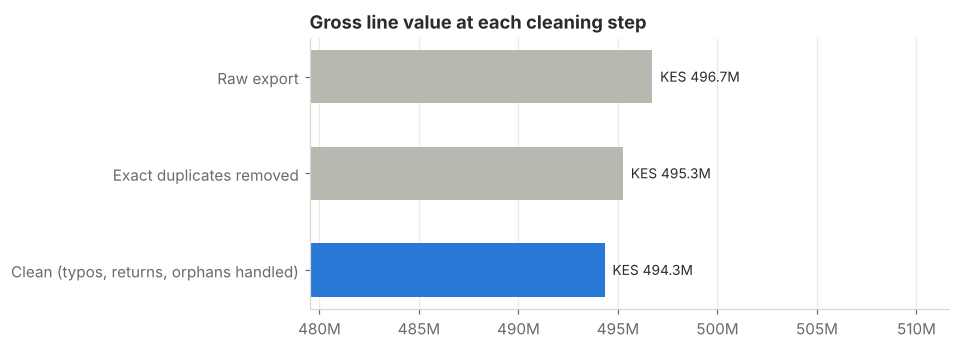

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
impact = pd.Series({"Raw export": raw_value, "after removing duplicates": None, "Clean sales lines": clean_value})
dup_value = (lambda d: (pd.to_numeric(d.quantity) * pd.to_numeric(d.unit_price)).sum())(raw["transaction_items"].drop_duplicates())
vals = [raw_value, dup_value, clean_value]; labels = ["Raw export", "Exact duplicates removed", "Clean (typos, returns, orphans handled)"]
ax.barh(labels[::-1], vals[::-1], color=[an.PRIMARY, an.CONTEXT, an.CONTEXT], height=.55)
for i, v in enumerate(vals[::-1]): ax.text(v, i, f"  {an.kes(v)}", va="center", fontsize=9)
ax.set_xlim(min(vals) * .97, max(vals) * 1.03); an.kes_axis(ax, "x")
ax.set_title("Gross line value at each cleaning step"); ax.grid(axis="y", visible=False)
an.save(fig, "cleaning_value_impact");

## 4. Inventory

In [7]:
inv, e6 = dc.clean_inventory(raw["inventory"], set(products.product_id), set(branches.branch_id))
print("inventory rows", len(raw["inventory"]), "->", len(inv), "| negatives corrected:", sum(1 for x in e6 if x[2].startswith("negative")))

inventory rows 249985 -> 249487 | negatives corrected: 50


## 5. The exception log (written by the pipeline)

In [8]:
an.sql_output('dq_b03_exception_log')

,source_table,issue,action_taken,records
0,customers,missing county,left NULL (reported as Unknown),360
1,customers,segment label casing,standardised,150
2,customers,exact duplicate row,removed duplicate copy,90
3,customers,placeholder registration date 1900-01-01,set to NULL,7
4,inventory,exact duplicate row,removed duplicate copy,498
5,inventory,negative stock count (sold before receipt posted),set to 0,50
6,products,non-standard category label,mapped to canonical category,18
7,products,leading/trailing whitespace in name,trimmed,12
8,products,missing brand,set to 'Unknown',6
9,products,missing unit_cost,imputed from category median cost ratio,3


## 6. Clean-layer validation: every check must be 0

In [9]:
checks = an.sql_output("dq_b01_integrity_summary")
assert checks.failures.sum() == 0, checks[checks.failures > 0]
checks

,check_name,failures
0,duplicate transaction_id,0
1,items without a transaction,0
2,transactions outside period,0
3,transactions before branch opening,0
4,purchases before customer registration,0
5,non-positive quantity or price,0
6,discount greater than line value,0
7,promotion line outside promotion dates,0
8,promotion line for a different product,0
9,inventory snapshot for unopened branch,0


In [10]:
an.sql_output('dq_b02_join_fanout_check')

,item_rows,view_rows,difference
0,1198181,1198181,0


The sales view has exactly as many rows as the line table, so the joins to transactions and products do not fan out. Every downstream total can be trusted not to double-count.